In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import math


df = pd.read_csv("Life_Expectancy.csv")

In [43]:
print("Shape -------- ")
print(df.shape)
print("Info -------- ")
print(df.info())
print("Describe -------- ")
print(df.describe()) # no values out of expected ranges
print("isna() count -------- ")
print(df.isna().sum()) # all values are present
print("Dupes count -------- ")
print(df.duplicated().sum()) # no duplicate values

Shape -------- 
(2864, 21)
Info -------- 
<class 'pandas.DataFrame'>
RangeIndex: 2864 entries, 0 to 2863
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Country                      2864 non-null   str    
 1   Region                       2864 non-null   str    
 2   Year                         2864 non-null   int64  
 3   Infant_deaths                2864 non-null   float64
 4   Under_five_deaths            2864 non-null   float64
 5   Adult_mortality              2864 non-null   float64
 6   Alcohol_consumption          2864 non-null   float64
 7   Hepatitis_B                  2864 non-null   int64  
 8   Measles                      2864 non-null   int64  
 9   BMI                          2864 non-null   float64
 10  Polio                        2864 non-null   int64  
 11  Diphtheria                   2864 non-null   int64  
 12  Incidents_HIV                2864 non-null   

In [44]:
# region location
region_list = []

for i  in df["Region"]:
    if i not in region_list:
        region_list.append(i)

# Europe is split into 2 regions, EU and Europe. Rest of the categories are uniform.
print(region_list)

['Middle East', 'European Union', 'Asia', 'South America', 'Central America and Caribbean', 'Rest of Europe', 'Africa', 'Oceania', 'North America']


In [45]:
# split the data frames by region

europe = df[df["Region"].isin(["European Union", "Rest of Europe"])].copy()
mid_east = df[df["Region"] == "Middle East"].copy()
asia = df[df["Region"] == "Asia"].copy
s_america = df[df["Region"] == "South America"].copy()
n_america = df[df["Region"] == "North America"].copy()
africa = df[df["Region"] == "Africa"].copy()
oceania = df[df["Region"] == "Oceania"].copy()


In [46]:
# How many countries do we have?
country_list = []

for i  in df["Country"]:
    if i not in country_list:
        country_list.append(i)

print(len(country_list))
# 179 Countries Reported.
# 193 UN recognised countries.
# 14 countries are missing -> This may impact regional analysis

179


In [47]:
# do we have all 16 years of observations for each country?
country_observed = list(df.groupby("Country")["Year"].count().items())
for country, count in country_observed:
    if count != 16:
        print(country, count)

# yes !

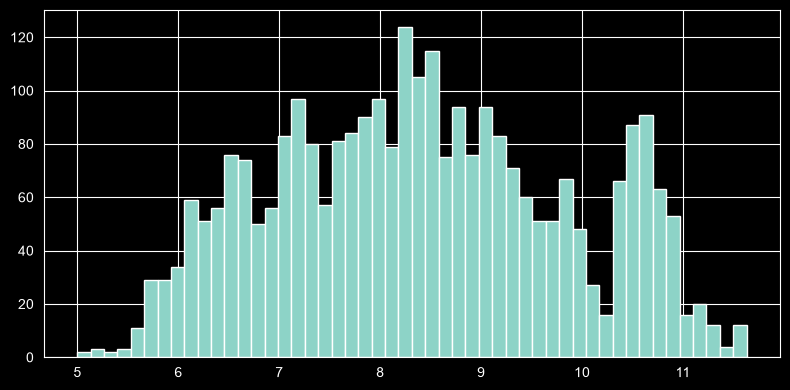

In [48]:
# Logging GDP per capita
df["ln_gdp"] = np.log(df["GDP_per_capita"])

#Data distribution of logged GDP per capita
df["ln_gdp"].hist(bins=50, figsize=(8, 4))
plt.tight_layout(); plt.show()


In [49]:
df.head()

,Country,Region,Year,Infant_deaths,Under_five_deaths,Adult_mortality,Alcohol_consumption,Hepatitis_B,Measles,BMI,...,Incidents_HIV,GDP_per_capita,Population_mln,Thinness_ten_nineteen_years,Thinness_five_nine_years,Schooling,Economy_status_Developed,Economy_status_Developing,Life_expectancy,ln_gdp
0,Turkiye,Middle East,2015,11.1,13.0,105.8240,1.32,97,65,27.8,...,0.08,11006,78.53,4.9,4.8,7.8,0,1,76.5,9.306196
1,Spain,European Union,2015,2.7,3.3,57.9025,10.35,97,94,26.0,...,0.09,25742,46.44,0.6,0.5,9.7,1,0,82.8,10.155879
2,India,Asia,2007,51.5,67.9,201.0765,1.57,60,35,21.2,...,0.13,1076,1183.21,27.1,28.0,5.0,0,1,65.4,6.981006
3,Guyana,South America,2006,32.8,40.5,222.1965,5.68,93,74,25.3,...,0.79,4146,0.75,5.7,5.5,7.9,0,1,67.0,8.329899
4,Israel,Middle East,2012,3.4,4.3,57.9510,2.89,97,89,27.0,...,0.08,33995,7.91,1.2,1.1,12.8,1,0,81.7,10.433969


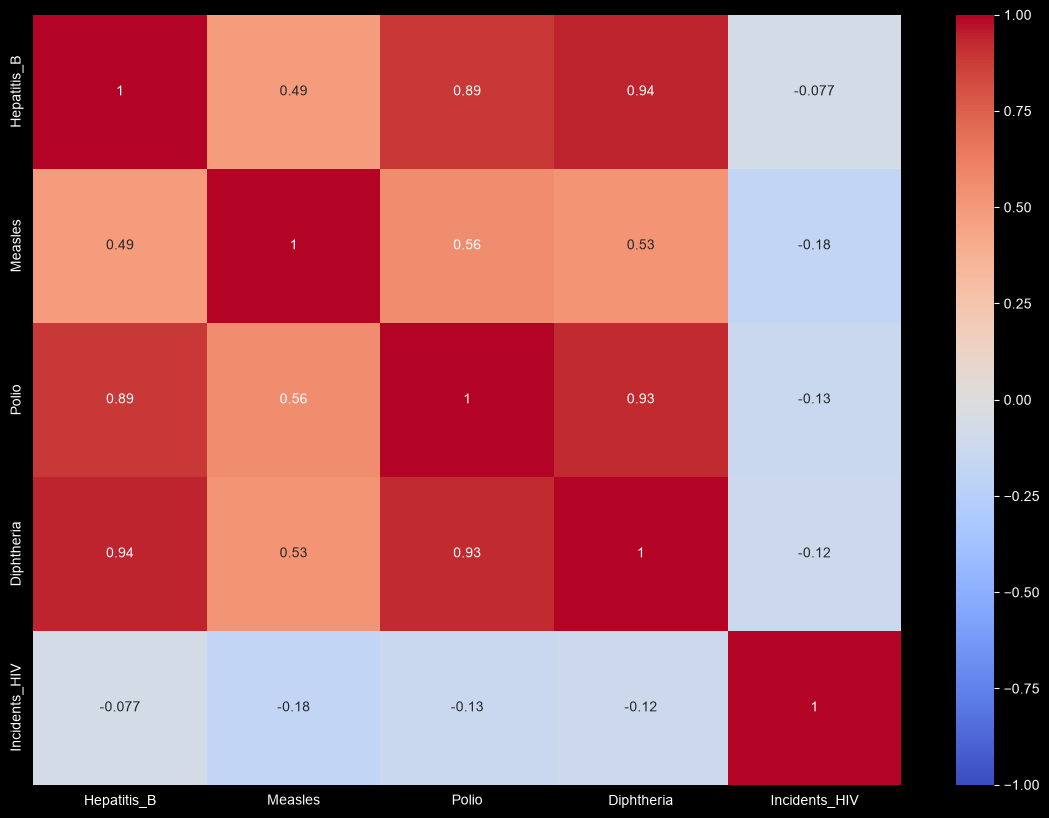

In [91]:
import seaborn as sns
import matplotlib.pyplot as plt

variables = [
    "Hepatitis_B",
    "Measles",
    "Polio",
    "Diphtheria",
    "Incidents_HIV",
]

corr = est[variables].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, cmap="coolwarm",
            vmin=-1, vmax=1)

plt.show()

In [51]:
#cols = ["Survived", "Sex", "Pclass", "Age", "Fare", "SibSp", "Parch"]
est = df.copy()       # same rows for every model

#est["age2"] = est["Age"]**2
#est["Child"] = np.where(est["Age"]<18,1,0)

m = smf.ols(
    "Life_expectancy ~ C(Country) + Alcohol_consumption + Hepatitis_B + Measles + BMI + Polio + Diphtheria + Incidents_HIV + GDP_per_capita + Population_mln + Thinness_ten_nineteen_years + Thinness_five_nine_years + Schooling + C(Economy_status_Developing)",
    data=est
).fit() # Will produce conventional OLS standard errors.
# Doesnt work with panel data - the observations are not independent.

# remove C(Economy_status_Developing
print(m.summary())

                            OLS Regression Results                            
Dep. Variable:        Life_expectancy   R-squared:                       0.986
Model:                            OLS   Adj. R-squared:                  0.985
Method:                 Least Squares   F-statistic:                     1008.
Date:                Wed, 25 Nov 2026   Prob (F-statistic):               0.00
Time:                        10:33:35   Log-Likelihood:                -4346.0
No. Observations:                2864   AIC:                             9074.
Df Residuals:                    2673   BIC:                         1.021e+04
Df Model:                         190                                         
Covariance Type:            nonrobust                                         
                                                   coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

/var/folders/mk/5bg9brwn0xsgxxyglk736msh0000gn/T/ipykernel_71498/1174197312.py:10: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit() # Will produce conventional OLS standard errors.


In [52]:
# FIXED EFFECTS MODEL

#cols = ["Survived", "Sex", "Pclass", "Age", "Fare", "SibSp", "Parch"]
est = df.copy()       # same rows for every model

#est["age2"] = est["Age"]**2
#est["Child"] = np.where(est["Age"]<18,1,0)

m = smf.ols(
    "Life_expectancy ~ C(Country) + Alcohol_consumption + Hepatitis_B + Measles + BMI + Polio + Diphtheria + Incidents_HIV + GDP_per_capita + Population_mln + Thinness_ten_nineteen_years + Thinness_five_nine_years + Schooling + C(Economy_status_Developing)",
    data=est
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df["Country"]}
) # Will produce conventional OLS standard errors.
# Doesnt work with panel data - the observations are not independent.

# remove C(Economy_status_Developing

print(m.summary())

# multicollinearity between explanatory variables

                            OLS Regression Results                            
Dep. Variable:        Life_expectancy   R-squared:                       0.986
Model:                            OLS   Adj. R-squared:                  0.985
Method:                 Least Squares   F-statistic:                     37.64
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           1.57e-42
Time:                        10:33:35   Log-Likelihood:                -4346.0
No. Observations:                2864   AIC:                             9074.
Df Residuals:                    2673   BIC:                         1.021e+04
Df Model:                         190                                         
Covariance Type:              cluster                                         
                                                   coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

/var/folders/mk/5bg9brwn0xsgxxyglk736msh0000gn/T/ipykernel_71498/3809354083.py:12: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(
/Users/samuelthomas/PycharmProjects/Economics_DataAnalytics /.venv/lib/python3.14/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 191, but rank is 12
  res = self.wald_test(


In [53]:
# Order panel data by country and year
df = df.sort_values(["Country", "Year"]).reset_index(drop=True)

# Log transformation of GDP per capita
df["Log_GDP"] = np.log(df["GDP_per_capita"])

# Combine childhood thinness indicators
df["Thinness"] = (
    df["Thinness_ten_nineteen_years"] +
    df["Thinness_five_nine_years"]
) / 2

# Explanatory variables
X = """
    Log_GDP + Schooling + Diphtheria
    + Incidents_HIV + BMI + I(BMI**2)
    + Alcohol_consumption + Thinness
"""

In [54]:
# POOLED OLD REGRESSION
# country clustered standard errors
model_1 = smf.ols(
    formula=f"Life_expectancy ~ {X}",
    data=df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df["Country"]}
)

print(model_1.summary())

                            OLS Regression Results                            
Dep. Variable:        Life_expectancy   R-squared:                       0.865
Model:                            OLS   Adj. R-squared:                  0.864
Method:                 Least Squares   F-statistic:                     165.1
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           3.89e-78
Time:                        10:33:35   Log-Likelihood:                -7619.9
No. Observations:                2864   AIC:                         1.526e+04
Df Residuals:                    2855   BIC:                         1.531e+04
Df Model:                           8                                         
Covariance Type:              cluster                                         
                          coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               7.7427    

In [55]:
# introduce country fixed effects
# each country gets its own intercept
# after introducing country fixed effects, the estimated association between GDP and life expectancy becomes smaller.

# pooled OLS : 2.992
# Country Fixed Effects : 1.485
model_2 = smf.ols(
    formula=f"Life_expectancy ~ {X} + C(Country)",
    data=df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df["Country"]}
)

print(model_2.summary())

                            OLS Regression Results                            
Dep. Variable:        Life_expectancy   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.988
Method:                 Least Squares   F-statistic:                     24.13
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           7.41e-25
Time:                        10:33:35   Log-Likelihood:                -4080.1
No. Observations:                2864   AIC:                             8534.
Df Residuals:                    2677   BIC:                             9649.
Df Model:                         186                                         
Covariance Type:              cluster                                         
                                                   coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

/Users/samuelthomas/PycharmProjects/Economics_DataAnalytics /.venv/lib/python3.14/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 186, but rank is 8
  res = self.wald_test(


In [56]:
# two way fixed effects regression
model_3 = smf.ols(
    formula=f"Life_expectancy ~ {X} + C(Country) + C(Year)",
    data=df
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df["Country"]}
)

print(model_3.summary())

                            OLS Regression Results                            
Dep. Variable:        Life_expectancy   R-squared:                       0.991
Model:                            OLS   Adj. R-squared:                  0.990
Method:                 Least Squares   F-statistic:                     31.53
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           8.11e-51
Time:                        10:33:35   Log-Likelihood:                -3721.7
No. Observations:                2864   AIC:                             7847.
Df Residuals:                    2662   BIC:                             9051.
Df Model:                         201                                         
Covariance Type:              cluster                                         
                                                   coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

/Users/samuelthomas/PycharmProjects/Economics_DataAnalytics /.venv/lib/python3.14/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 201, but rank is 23
  res = self.wald_test(


In [57]:
#introducing lag

variables = [
    "Log_GDP",
    "Schooling",
    "Diphtheria",
    "Incidents_HIV",
    "BMI",
    "Alcohol_consumption",
    "Thinness"
]

# Set lag length
k = 3

# Create lagged variables within each country
df_lag = df.copy()

for var in variables:
    df_lag[f"{var}_lag"] = (
        df_lag.groupby("Country")[var].shift(k)
    )

# Remove observations without historical data
df_lag = df_lag.dropna()

X_lag = """
    Log_GDP_lag + Schooling_lag + Diphtheria_lag
    + Incidents_HIV_lag + BMI_lag + I(BMI_lag**2)
    + Alcohol_consumption_lag + Thinness_lag
"""

model_4 = smf.ols(
    formula=f"""
        Life_expectancy ~ {X_lag}
        + C(Country) + C(Year)
    """,
    data=df_lag
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_lag["Country"]}
)

print(model_4.summary())

                            OLS Regression Results                            
Dep. Variable:        Life_expectancy   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.994
Method:                 Least Squares   F-statistic:                     46.26
Date:                Wed, 25 Nov 2026   Prob (F-statistic):           1.03e-59
Time:                        10:33:35   Log-Likelihood:                -2392.1
No. Observations:                2327   AIC:                             5182.
Df Residuals:                    2128   BIC:                             6327.
Df Model:                         198                                         
Covariance Type:              cluster                                         
                                                   coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

/Users/samuelthomas/PycharmProjects/Economics_DataAnalytics /.venv/lib/python3.14/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 198, but rank is 20
  res = self.wald_test(


In [58]:
from statsmodels.iolib.summary2 import summary_col

results = summary_col(
    [model_1, model_2, model_3],
    model_names=["Pooled OLS", "Country FE", "Two-way FE"],
    stars=True,
    float_format="%.3f",
    regressor_order=[
        "Log_GDP",
        "Schooling",
        "Diphtheria",
        "Incidents_HIV",
        "BMI",
        "I(BMI ** 2)",
        "Alcohol_consumption",
        "Thinness"
    ],
    drop_omitted=True,
    info_dict={
        "Observations": lambda x: f"{int(x.nobs)}",
        "R-squared": lambda x: f"{x.rsquared:.3f}"
    }
)

print(results)


                    Pooled OLS Country FE Two-way FE
----------------------------------------------------
Log_GDP             2.992***   1.485***   0.733*    
                    (0.257)    (0.461)    (0.436)   
Schooling           0.528***   0.493***   -0.211    
                    (0.127)    (0.112)    (0.135)   
Diphtheria          0.144***   0.038***   0.036***  
                    (0.019)    (0.012)    (0.010)   
Incidents_HIV       -1.518***  -1.169***  -1.044*** 
                    (0.128)    (0.188)    (0.178)   
BMI                 1.401      15.309***  12.895*** 
                    (2.117)    (2.703)    (2.396)   
I(BMI ** 2)         -0.022     -0.262***  -0.259*** 
                    (0.041)    (0.052)    (0.045)   
Alcohol_consumption -0.144**   -0.130     -0.027    
                    (0.073)    (0.085)    (0.079)   
Thinness            0.069      -0.008     -0.004    
                    (0.063)    (0.033)    (0.027)   
R-squared           0.865      0.989      0.9

71.46368715083798


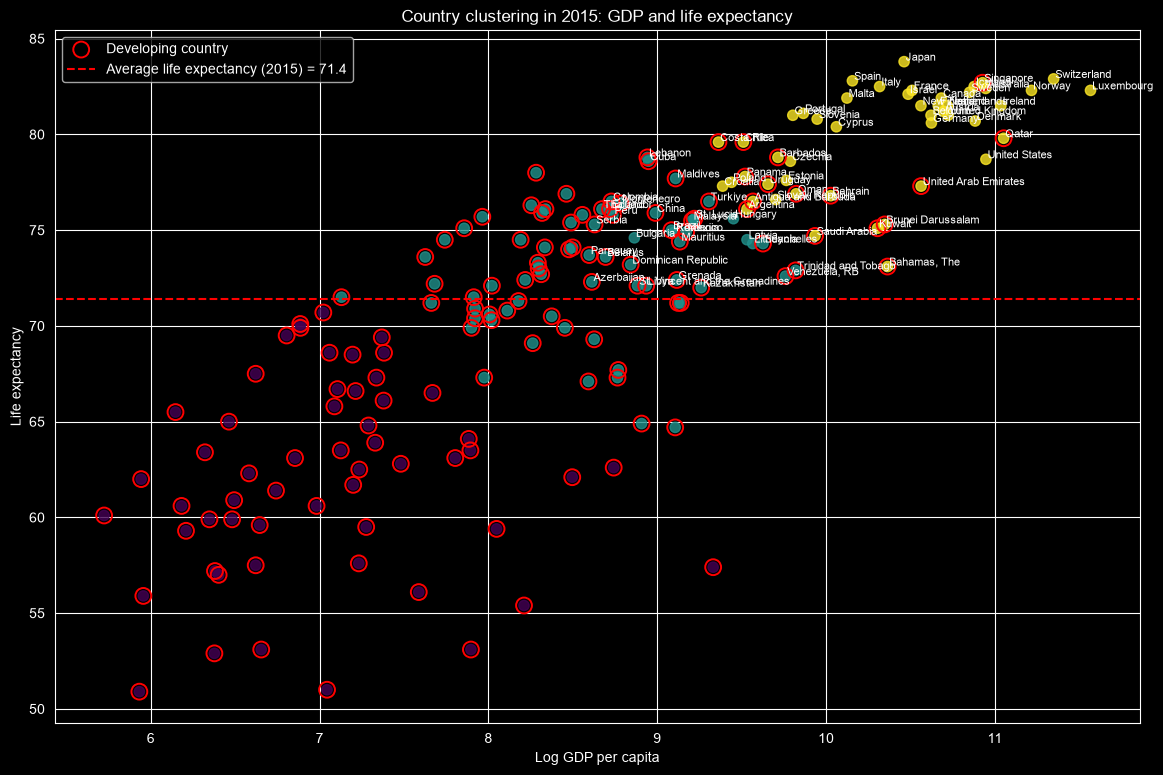

In [77]:

# Select a single year
year = 2015
est = df[df["Year"] == year].copy()

# Log GDP per capita
est["Log_GDP"] = np.log(est["GDP_per_capita"])

# Clustering variables
X_cluster = est[["Log_GDP", "Life_expectancy"]]

# Standardise for clustering
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# K-means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
est["Cluster"] = kmeans.fit_predict(X_scaled)

# Subset of developing countries
developing = est[est["Economy_status_Developing"] == 1]

# Average life expectancy in 2015
avg_le_2015 = est["Life_expectancy"].mean()
print(avg_le_2015)   # should be about 71.4

# Plot
fig, ax = plt.subplots(figsize=(14, 9))

# Main clustered scatter
scatter = ax.scatter(
    est["Log_GDP"],
    est["Life_expectancy"],
    c=est["Cluster"],
    cmap="viridis",
    s=55,
    alpha=0.8
)

# Red circles around developing countries
ax.scatter(
    developing["Log_GDP"],
    developing["Life_expectancy"],
    facecolors="none",
    edgecolors="red",
    s=130,
    linewidths=1.4,
    label="Developing country"
)

# Horizontal red line at average life expectancy
ax.axhline(
    y=71.4,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Average life expectancy (2015) = 71.4"
)

# Define "high GDP" as above the median
gdp_cutoff = est["Log_GDP"].median()

interesting = est[
    (est["Life_expectancy"] > 71.4) &
    (est["Log_GDP"] > gdp_cutoff)
    ]

for _, row in interesting.iterrows():
    ax.text(
        row["Log_GDP"] + 0.01,
        row["Life_expectancy"] + 0.05,
        row["Country"],
        fontsize=8
    )

ax.set_xlabel("Log GDP per capita")
ax.set_ylabel("Life expectancy")
ax.set_title("Country clustering in 2015: GDP and life expectancy")
ax.legend()
plt.show()

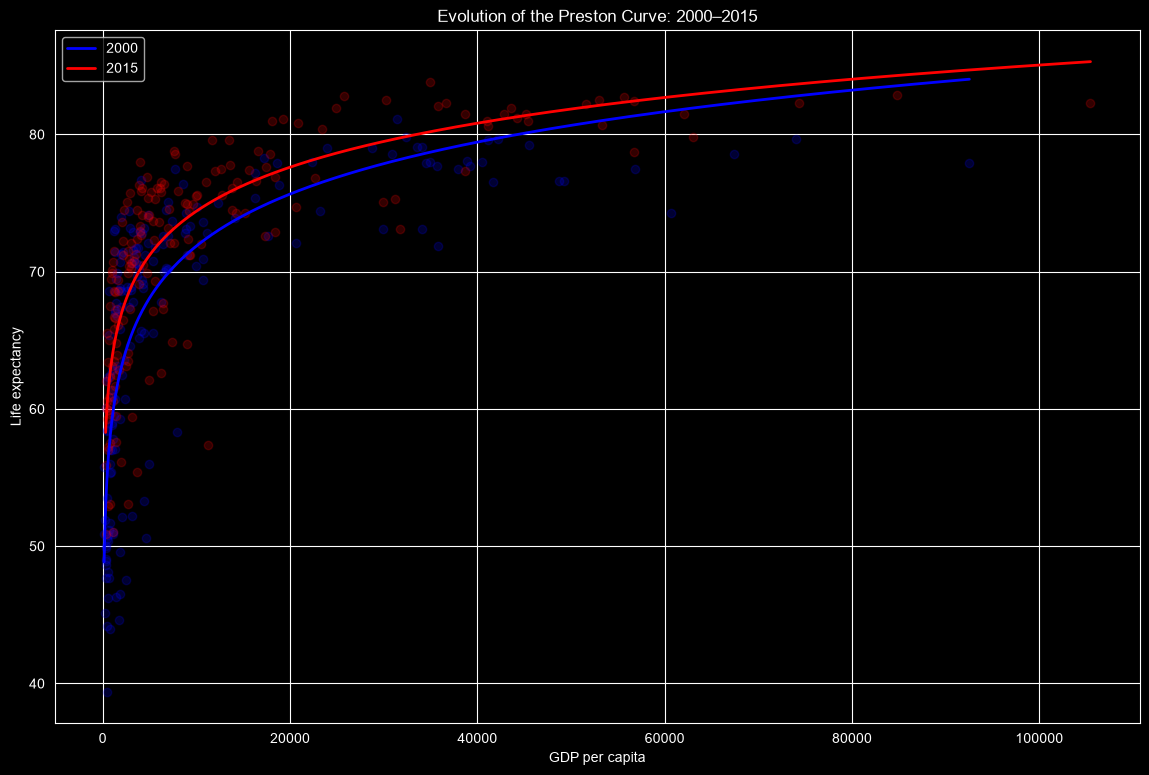

In [87]:
fig, ax = plt.subplots(figsize=(14, 9))

for year, colour in [(2000, "blue"), (2015, "red")]:

    est = df[df["Year"] == year]

    x = est["GDP_per_capita"]
    y = est["Life_expectancy"]

    slope, intercept = np.polyfit(np.log(x), y, 1)

    x_line = np.linspace(x.min(), x.max(), 1000)

    ax.scatter(x, y, color=colour, alpha=0.2)

    ax.plot(
        x_line,
        intercept + slope * np.log(x_line),
        color=colour,
        linewidth=2,
        label=str(year)
    )

ax.set_xlabel("GDP per capita")
ax.set_ylabel("Life expectancy")
ax.set_title("Evolution of the Preston Curve: 2000–2015")
ax.legend()

plt.show()

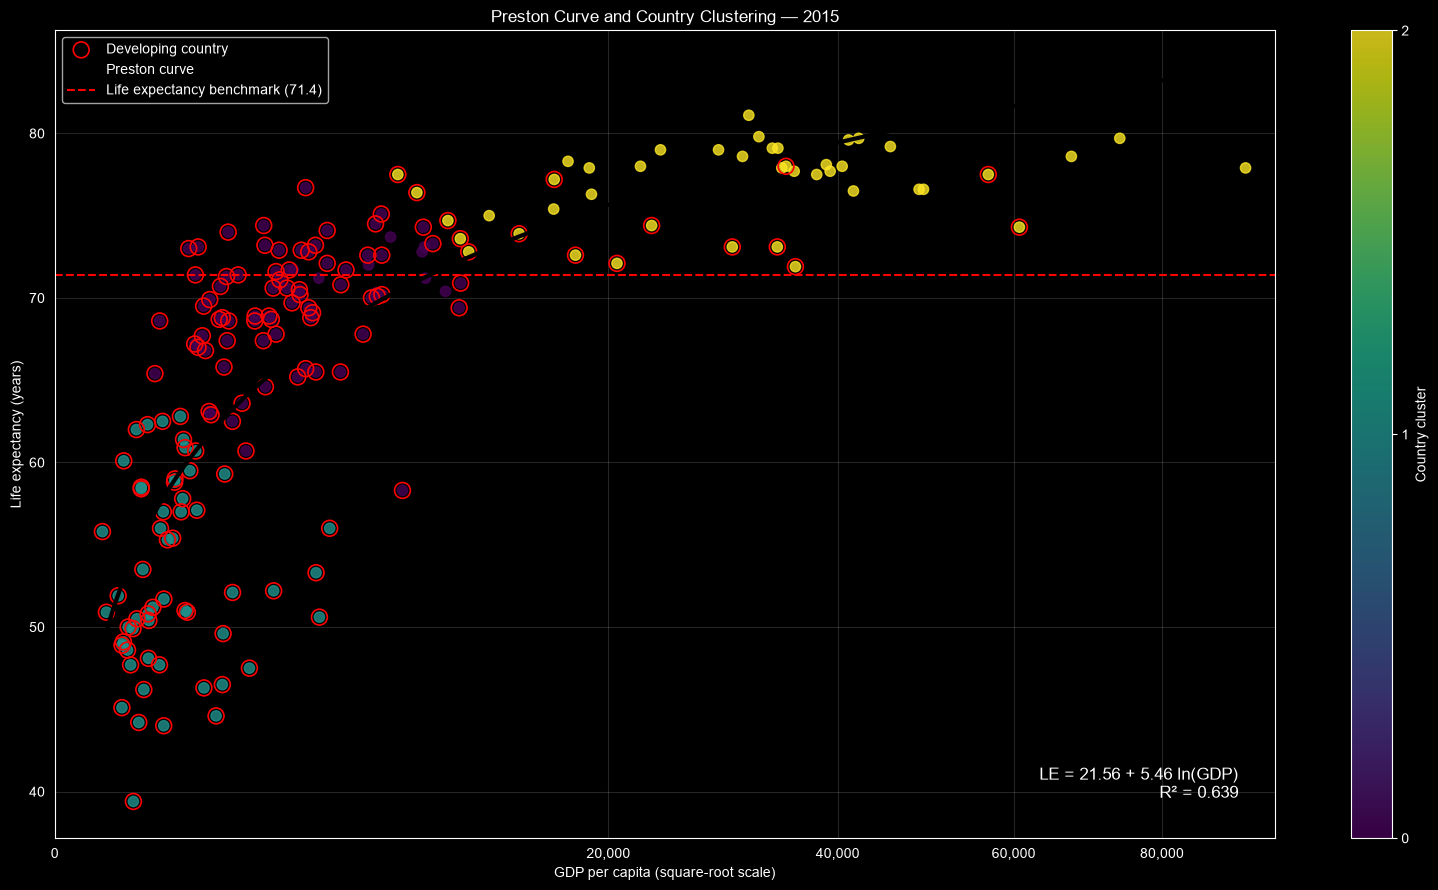

In [89]:


# Close existing figures
plt.close("all")

# Select 2015
year = 2000
est = df[df["Year"] == year].copy()

# Remove invalid observations
est = est.dropna(subset=["GDP_per_capita", "Life_expectancy"])
est = est[est["GDP_per_capita"] > 0].copy()

# Log GDP per capita
est["Log_GDP"] = np.log(est["GDP_per_capita"])

# Clustering variables
X_cluster = est[["Log_GDP", "Life_expectancy"]]

# Standardise variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# K-means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
est["Cluster"] = kmeans.fit_predict(X_scaled)

# Developing countries
developing = est[est["Economy_status_Developing"] == 1]

# Create figure and axes
fig, ax = plt.subplots(figsize=(16, 9))

# Plot country clusters
scatter = ax.scatter(
    est["GDP_per_capita"],
    est["Life_expectancy"],
    c=est["Cluster"],
    cmap="viridis",
    s=55,
    alpha=0.8
)

# Red circles around developing countries
ax.scatter(
    developing["GDP_per_capita"],
    developing["Life_expectancy"],
    facecolors="none",
    edgecolors="red",
    s=130,
    linewidths=1.2,
    label="Developing country"
)

# Fit Preston curve
x = est["GDP_per_capita"]
y = est["Life_expectancy"]

slope, intercept = np.polyfit(np.log(x), y, 1)

x_line = np.geomspace(x.min(), x.max(), 1000)
y_line = intercept + slope * np.log(x_line)

# Plot Preston curve
ax.plot(
    x_line,
    y_line,
    color="black",
    linewidth=3,
    zorder=10,
    label="Preston curve"
)

# Average life expectancy benchmark
ax.axhline(
    y=71.4,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Life expectancy benchmark (71.4)"
)

# R-squared
r_squared = np.corrcoef(np.log(x), y)[0, 1]**2

# Display regression equation
ax.text(
    0.97, 0.05,
    f"LE = {intercept:.2f} + {slope:.2f} ln(GDP)\n"
    f"R² = {r_squared:.3f}",
    transform=ax.transAxes,
    horizontalalignment="right",
    fontsize=12
)

# Square-root GDP scale
ax.set_xscale(
    "function",
    functions=(np.sqrt, np.square)
)

# Axis limits and formatting
ax.set_xlim(0, x.max() * 1.05)

ax.xaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

ax.set_xlabel("GDP per capita (square-root scale)")
ax.set_ylabel("Life expectancy (years)")
ax.set_title("Preston Curve and Country Clustering — 2015")

# Cluster colour legend
fig.colorbar(scatter, ax=ax, ticks=[0, 1, 2], label="Country cluster")

ax.grid(alpha=0.15)
ax.legend()

fig.tight_layout()
plt.show()

# diminshing margial returns of GDP per capita on life expectancy (Preston curve)

# 2000 - 2015 : see what countries move from one cluster to another.

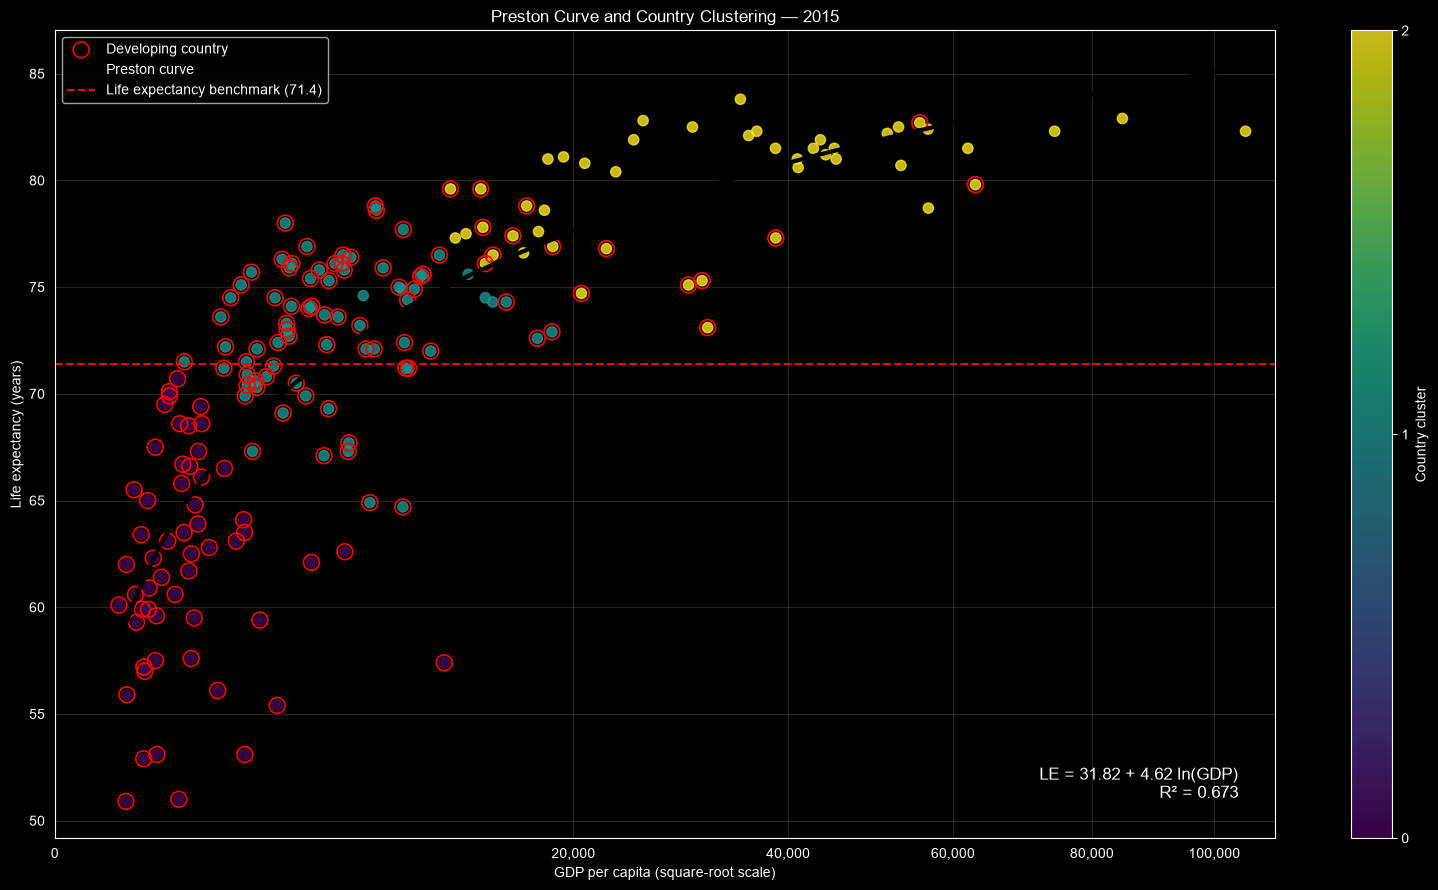

In [90]:


# Close existing figures
plt.close("all")

# Select 2015
year = 2015
est = df[df["Year"] == year].copy()

# Remove invalid observations
est = est.dropna(subset=["GDP_per_capita", "Life_expectancy"])
est = est[est["GDP_per_capita"] > 0].copy()

# Log GDP per capita
est["Log_GDP"] = np.log(est["GDP_per_capita"])

# Clustering variables
X_cluster = est[["Log_GDP", "Life_expectancy"]]

# Standardise variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

# K-means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
est["Cluster"] = kmeans.fit_predict(X_scaled)

# Developing countries
developing = est[est["Economy_status_Developing"] == 1]

# Create figure and axes
fig, ax = plt.subplots(figsize=(16, 9))

# Plot country clusters
scatter = ax.scatter(
    est["GDP_per_capita"],
    est["Life_expectancy"],
    c=est["Cluster"],
    cmap="viridis",
    s=55,
    alpha=0.8
)

# Red circles around developing countries
ax.scatter(
    developing["GDP_per_capita"],
    developing["Life_expectancy"],
    facecolors="none",
    edgecolors="red",
    s=130,
    linewidths=1.2,
    label="Developing country"
)

# Fit Preston curve
x = est["GDP_per_capita"]
y = est["Life_expectancy"]

slope, intercept = np.polyfit(np.log(x), y, 1)

x_line = np.geomspace(x.min(), x.max(), 1000)
y_line = intercept + slope * np.log(x_line)

# Plot Preston curve
ax.plot(
    x_line,
    y_line,
    color="black",
    linewidth=3,
    zorder=10,
    label="Preston curve"
)

# Average life expectancy benchmark
ax.axhline(
    y=71.4,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Life expectancy benchmark (71.4)"
)

# R-squared
r_squared = np.corrcoef(np.log(x), y)[0, 1]**2

# Display regression equation
ax.text(
    0.97, 0.05,
    f"LE = {intercept:.2f} + {slope:.2f} ln(GDP)\n"
    f"R² = {r_squared:.3f}",
    transform=ax.transAxes,
    horizontalalignment="right",
    fontsize=12
)

# Square-root GDP scale
ax.set_xscale(
    "function",
    functions=(np.sqrt, np.square)
)

# Axis limits and formatting
ax.set_xlim(0, x.max() * 1.05)

ax.xaxis.set_major_formatter(
    StrMethodFormatter("{x:,.0f}")
)

ax.set_xlabel("GDP per capita (square-root scale)")
ax.set_ylabel("Life expectancy (years)")
ax.set_title("Preston Curve and Country Clustering — 2015")

# Cluster colour legend
fig.colorbar(scatter, ax=ax, ticks=[0, 1, 2], label="Country cluster")

ax.grid(alpha=0.15)
ax.legend()

fig.tight_layout()
plt.show()

# diminshing margial returns of GDP per capita on life expectancy (Preston curve)

# 2000 - 2015 : see what countries move from one cluster to another.

# k means clustering
